# Why 95% accuracy can be useless

**A worked example of class imbalance in a rare-event prediction problem.**

When an outcome is rare, such as a serious adverse event in a study or a large claim in an insurance portfolio, a model can score very high accuracy while catching none of the cases it was built to find.

This notebook shows that with:

1. A "predict nothing ever happens" baseline that scores about 95% accuracy
2. A simple logistic regression that scores *lower* accuracy but actually finds events
3. Precision, recall and the precision-recall curve as better ways to judge a model
4. How choosing a decision threshold depends on what each mistake costs

> **Data note:** all data here is **synthetic**, generated with `sklearn.datasets.make_classification`. It does not represent any real patients, study, or organisation. The features are anonymous numbers; the "adverse event" framing is only a label to make the example concrete.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score,
)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

## 1. Create a rare-event dataset

10,000 synthetic "patients", 20 numeric features, and an outcome that occurs in about 5% of cases.

In [2]:
X, y = make_classification(
    n_samples=10_000,
    n_features=20,
    n_informative=6,
    n_redundant=4,
    weights=[0.95, 0.05],   # ~5% of records have the event
    flip_y=0.01,            # a little label noise, as in real data
    class_sep=0.8,
    random_state=RANDOM_STATE,
)

counts = pd.Series(y).value_counts().rename({0: "No event", 1: "Event"})
print(counts.to_string())
print(f"\nEvent rate: {y.mean():.1%}")

No event    9453
Event        547

Event rate: 5.5%


Split into three sets:

| Set | Share | Used for |
| --- | --- | --- |
| Train | 52.5% | Fitting the model |
| Validation | 17.5% | Choosing the decision threshold (Section 6) |
| Test | 30% | Reporting final results, used once |

Keeping the test set untouched until the end matters: if we tuned the threshold on the test set and then reported results on it, those results would be optimistic.

`stratify` keeps the same event rate in every set, which matters when events are rare: an unstratified split can leave a set with very few positives.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE
)

for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11}: {len(ys):>5,} records, {ys.sum():>3} events ({ys.mean():.1%})")

Train      : 5,250 records, 287 events (5.5%)
Validation : 1,750 records,  96 events (5.5%)
Test       : 3,000 records, 164 events (5.5%)


## 2. The useless baseline: always predict "no event"

`DummyClassifier(strategy="most_frequent")` ignores the features and predicts the majority class for everyone.

In [4]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred_base):.1%}")
print(f"Recall   : {recall_score(y_test, y_pred_base):.1%}   <- events caught")
print(f"Precision: {precision_score(y_test, y_pred_base, zero_division=0):.1%}")

Accuracy : 94.5%
Recall   : 0.0%   <- events caught
Precision: 0.0%


High accuracy, zero events caught. Accuracy here mostly measures how common the "no event" group is.

## 3. A real model: logistic regression

`class_weight="balanced"` tells the model that mistakes on the rare class count more, instead of letting the majority class dominate training.

In [5]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
).fit(X_train, y_train)

y_pred_lr = model.predict(X_test)                # default threshold of 0.5
y_score_lr = model.predict_proba(X_test)[:, 1]   # test-set probabilities
y_score_val = model.predict_proba(X_val)[:, 1]   # validation probabilities, for Section 6

print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.1%}")
print(f"Recall   : {recall_score(y_test, y_pred_lr):.1%}   <- events caught")
print(f"Precision: {precision_score(y_test, y_pred_lr):.1%}")

Accuracy : 73.1%
Recall   : 73.8%   <- events caught
Precision: 13.7%


## 4. Side by side

The model with *lower* accuracy is the one that is actually useful.

In [6]:
def summarise(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall (events caught)": recall_score(y_true, y_pred),
        "Precision (flags that were real)": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Events missed (FN)": fn,
        "False alarms (FP)": fp,
    }

results = pd.DataFrame([
    summarise("Always 'no event'", y_test, y_pred_base),
    summarise("Logistic regression (balanced)", y_test, y_pred_lr),
]).set_index("Model")

pct_cols = ["Accuracy", "Recall (events caught)", "Precision (flags that were real)", "F1"]
results.style.format({c: "{:.1%}" for c in pct_cols})

,Accuracy,Recall (events caught),Precision (flags that were real),F1,Events missed (FN),False alarms (FP)
Model,,,,,,
Always 'no event',94.5%,0.0%,0.0%,0.0%,164,0
Logistic regression (balanced),73.1%,73.8%,13.7%,23.1%,43,764


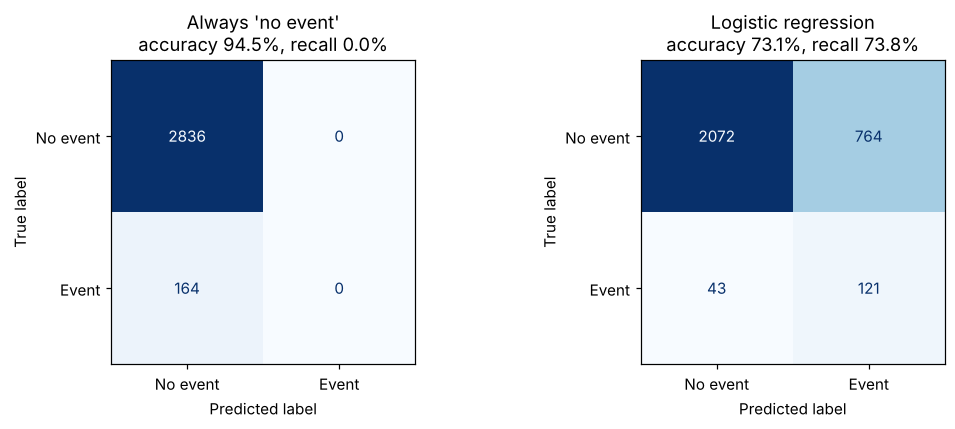

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("Always 'no event'", y_pred_base),
                                   ("Logistic regression", y_pred_lr)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No event", "Event"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_test, pred):.1%}, "
                 f"recall {recall_score(y_test, pred):.1%}")
plt.tight_layout()
plt.savefig("confusion_matrices.png", bbox_inches="tight")
plt.show()

## 5. Precision-recall curve

For rare outcomes, the precision-recall curve is more informative than the ROC curve, because it focuses on how the model performs on the positive class. A model with no skill sits at precision equal to the event rate (the dashed line). **Average precision (AP)** summarises the curve in one number.

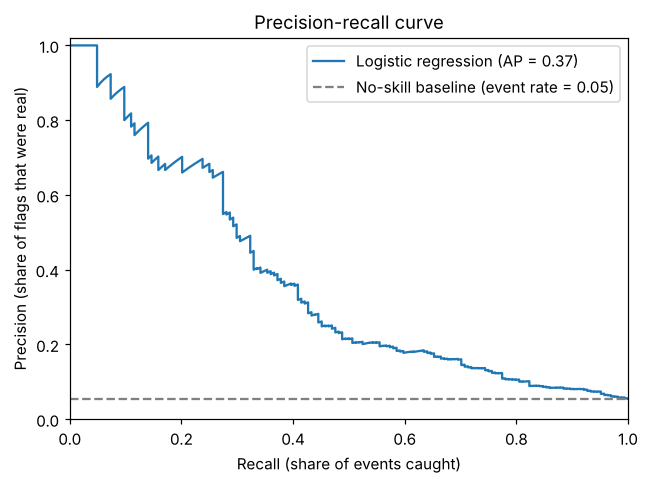

In [8]:
precision, recall, thresholds = precision_recall_curve(y_test, y_score_lr)
ap = average_precision_score(y_test, y_score_lr)
prevalence = y_test.mean()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(recall, precision, label=f"Logistic regression (AP = {ap:.2f})")
ax.axhline(prevalence, linestyle="--", color="grey",
           label=f"No-skill baseline (event rate = {prevalence:.2f})")
ax.set_xlabel("Recall (share of events caught)")
ax.set_ylabel("Precision (share of flags that were real)")
ax.set_title("Precision-recall curve")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("precision_recall_curve.png", bbox_inches="tight")
plt.show()

## 6. Choosing a threshold is a cost decision

By default, a model flags a case when its predicted probability is above 0.5. That number is arbitrary. The right threshold depends on what each kind of mistake costs.

Below, as a purely **illustrative assumption**, a missed event costs 10 times as much as a false alarm. Change `COST_FN` and `COST_FP` to see how the best threshold moves.

**The threshold is chosen on the validation set, then applied once to the test set.** Choosing it on the test set would make the reported cost look better than it really is.

In [9]:
COST_FN = 10   # cost of missing a real event (illustrative)
COST_FP = 1    # cost of a false alarm (illustrative)

def cost_at(y_true, scores, t):
    pred = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Threshold": t, "Events caught": tp, "Events missed": fn,
            "False alarms": fp, "Recall": tp / (tp + fn),
            "Total cost": fn * COST_FN + fp * COST_FP}

# Step 1: search thresholds on the VALIDATION set
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
val_df = pd.DataFrame([cost_at(y_val, y_score_val, t) for t in thresholds])
best_t = val_df.loc[val_df["Total cost"].idxmin(), "Threshold"]
print(f"Threshold chosen on validation set: {best_t:.2f}")

val_df.style.format({"Recall": "{:.1%}"}).highlight_min(subset="Total cost", color="#d4edda")

Threshold chosen on validation set: 0.65


,Threshold,Events caught,Events missed,False alarms,Recall,Total cost
0,0.050000,96,0,1623,100.0%,1623
1,0.100000,96,0,1527,100.0%,1527
2,0.150000,94,2,1365,97.9%,1385
3,0.200000,92,4,1209,95.8%,1249
4,0.250000,91,5,1055,94.8%,1105
5,0.300000,88,8,909,91.7%,989
6,0.350000,86,10,755,89.6%,855
7,0.400000,80,16,641,83.3%,801
8,0.450000,79,17,538,82.3%,708
9,0.500000,75,21,429,78.1%,639


Now apply that threshold **once** to the untouched test set, and compare it with the baseline and with the default threshold of 0.5.

In [10]:
base_cost = y_test.sum() * COST_FN   # baseline misses every event, raises no false alarms

final = pd.DataFrame([
    {"Approach": "Always 'no event'", "Threshold": None,
     "Events caught": 0, "Events missed": int(y_test.sum()), "False alarms": 0,
     "Recall": 0.0, "Total cost": base_cost},
    {"Approach": "Logistic regression, default", **cost_at(y_test, y_score_lr, 0.5)},
    {"Approach": "Logistic regression, tuned on validation", **cost_at(y_test, y_score_lr, best_t)},
]).set_index("Approach")

final.style.format({"Recall": "{:.1%}", "Threshold": "{:.2f}"}, na_rep="n/a")

,Threshold,Events caught,Events missed,False alarms,Recall,Total cost
Approach,,,,,,
Always 'no event',n/a,0,164,0,0.0%,1640
"Logistic regression, default",0.50,121,43,764,73.8%,1194
"Logistic regression, tuned on validation",0.65,86,78,333,52.4%,1113


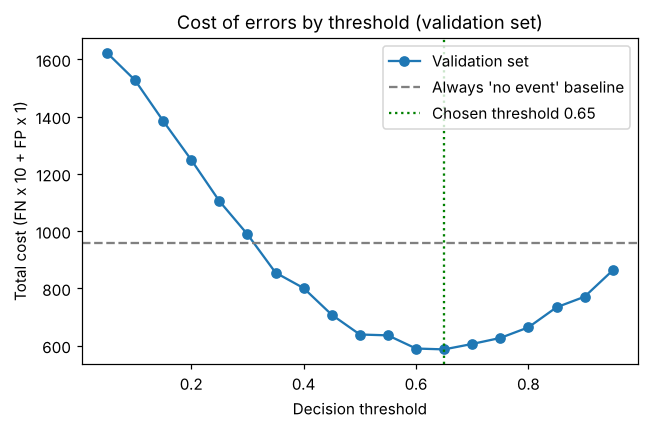

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(val_df["Threshold"], val_df["Total cost"], marker="o", label="Validation set")
ax.axhline(y_val.sum() * COST_FN, linestyle="--", color="grey",
           label="Always 'no event' baseline")
ax.axvline(best_t, linestyle=":", color="green", label=f"Chosen threshold {best_t:.2f}")
ax.set_xlabel("Decision threshold")
ax.set_ylabel(f"Total cost (FN x {COST_FN} + FP x {COST_FP})")
ax.set_title("Cost of errors by threshold (validation set)")
ax.legend()
plt.tight_layout()
plt.savefig("cost_by_threshold.png", bbox_inches="tight")
plt.show()

Two points worth noticing:

- **At low thresholds the model costs more than doing nothing**, because it floods the system with false alarms. A model used badly can be worse than no model.
- **The best threshold is above 0.5** because `class_weight="balanced"` inflates predicted probabilities for the rare class. Those probabilities are therefore not calibrated: a score of 0.6 does not mean a 60% chance of an event.

## Takeaways

- **Accuracy rewards the majority class.** With a 5% event rate, predicting "nothing happens" scores about 95% while catching nothing.
- **Recall and precision answer the real questions:** how many events did we catch, and how many flags were real?
- **Use the precision-recall curve and average precision** to compare models on rare outcomes; compare against the event rate, not against 50%.
- **The threshold is a business or clinical decision.** It should reflect what a missed event costs compared with a false alarm, and that should be agreed before the model is built.
- **Tune on validation, report on test.** Anything chosen by looking at results, including a threshold, must be chosen on data the final evaluation never sees.

*Synthetic data, illustrative costs. Built as a companion to a LinkedIn post on class imbalance.*